# Pollution — descriptives (sensor panel)

**Question.** How does upstream land-cover change affect river water quality?
**Unit.** One water-quality sample: monitoring station × sample datetime (`data/assembly/sensor_panel.parquet`).

This notebook collects the descriptive evidence needed to *choose* the model in
[`02_analysis.ipynb`](02_analysis.ipynb), rather than assuming it. Each section ends with
an **→ Informs** note naming the modelling parameter it pins down; §11 collects them into
one decision table. Fill the *Decision* column there after reading the output, and carry
the choices into `02_analysis`.

| § | Topic | Informs |
|---|---|---|
| 1 | Sample construction | estimation window, drops |
| 2 | Panel structure & sampling | unit of analysis (sample vs station-year), panel restrictions, seasonal FE |
| 3 | Outcome coverage | candidate outcome set |
| 4 | Outcome distributions | transforms, trimming, detection limits |
| 5 | Outcome variance decomposition | FE structure, aggregation |
| 6 | Land-cover exposure variation | which classes are identified, ALR vs shares, FE strength |
| 7 | Upstream distance structure | kernel / bandwidth, distance-band coefficients |
| 8 | Climate & streamflow controls | control set, windows, bad-control risk |
| 9 | Inference structure | cluster level, few-cluster corrections |
| 10 | Raw within-station associations | sign/shape priors, functional form |
| 11 | Decision table | — |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import descriptives as desc
from src.analysis import panels

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

### Screening parameters
Everything downstream that says "candidate" or "identifying" is a function of these.
Adjust and re-run rather than editing the tables by hand.

In [2]:
# A station identifies a land-cover effect under station FE only if it is
# sampled often enough, in enough distinct years, for upstream land cover to
# have changed between its samples.
MIN_SAMPLES_PER_STATION = 8
MIN_YEARS_PER_STATION = 3
# An analyte enters the candidate outcome set with at least this many identifying stations.
MIN_IDENTIFYING_STATIONS = 100

# Hypothesis-driven outcome sets carried over from 02_analysis, checked against the data in §3.
PRIOR_OUTCOME_GROUPS = {
    "pasture": [
        "thermotolerant_coliforms", "fecal_coliforms", "escherichia",
        "total_nitrogen", "ammoniacal_nitrogen", "total_phosphorus",
        "biochemical_oxygen_demand", "chemical_oxygen_demand",
        "chlorophyll", "cyanobacteria_density",
        "turbidity", "total_suspended_solids", "dissolved_oxygen",
    ],
    "mining": [
        "arsenic", "cadmium", "lead", "mercury", "manganese", "copper", "zinc",
        "aluminum", "sulfates", "electrical_conductivity",
        "total_suspended_solids", "turbidity", "ph", "dissolved_oxygen",
    ],
}

## 1. Sample construction

In [3]:
raw = pd.read_parquet(panels.SENSOR_PANEL_PATH, columns=["station_code", "datetime", "year"])
first_year, last_year = panels.EXPOSURE_YEARS
steps = {"assembled sensor_panel": len(raw)}
raw = raw.dropna(subset=["datetime"])
steps["non-null sample datetime"] = len(raw)
raw = raw[raw["year"].between(first_year, last_year)]
steps[f"year in {first_year}–{last_year} (land-cover & climate coverage)"] = len(raw)
display(pd.Series(steps, name="rows").to_frame())

s = panels.load_sensor_panel()
s["biome_year"] = s["biome"] + "_" + s["year"].astype(str)
ANALYTES = panels.sensor_analyte_columns()
TYPE_GROUP = panels.analyte_type_groups(ANALYTES)
print(f"{len(s):,} samples · {s.station_code.nunique():,} stations · "
      f"{s.system_id.nunique():,} river systems · {len(ANALYTES)} analytes")

,rows
assembled sensor_panel,209712
non-null sample datetime,209159
year in 1985–2024 (land-cover & climate coverage),193826


193,826 samples · 6,201 stations · 261 river systems · 131 analytes


Missingness of the exposure and control blocks *inside* the window, by biome. Stations missing land cover entirely are usually ones that did not snap to the river network.

In [4]:
blocks = {"land_cover": "lc_forest", "climate": "tp_mean_day", "system_id": "system_id",
          "trench_id": "trench_id", "streamflow": "streamflow_discharge_day"}
missing = s[list(blocks.values())].isna().set_axis(list(blocks), axis=1)
display(missing.groupby(s["biome"]).mean().assign(n=s.groupby("biome").size()))

station_lc = s.groupby("station_code")["lc_forest"].apply(lambda x: x.notna().any())
print(f"Stations with no land cover in any sample: {(~station_lc).sum():,} of {len(station_lc):,}")

,land_cover,climate,system_id,trench_id,streamflow,n
biome,,,,,,
Amazônia,0.02737,0.02807,0.01759,0.01759,0.04547,15747
Caatinga,0.02792,0.03021,0.0001241,0.0001241,0.02916,16120
Cerrado,0.04646,0.05345,0.003684,0.003684,0.01039,45333
Mata Atlântica,0.06065,0.06256,0.0008611,0.0008611,0.07323,107998
Pampa,0.1065,0.1065,0.04515,0.04515,0.232,4496
Pantanal,0.04889,0.0697,0.04889,0.04889,0.04889,4132


Stations with no land cover in any sample: 428 of 6,201


**Findings (run of 2026-10-21).** Restricting to 1985–2024 drops 7.6% of assembled samples: the 553 without a date, plus
pre-1985 and 2025–26 samples, which have no land cover or climate. Inside the window,
3–11% of samples lack exposure. Missingness is highest in Pampa (11%) and Mata
Atlântica (6%), and comes mostly from 428 of 6,201 stations that never snap to the river
network. It is station-level rather than sample-level, so complete-case estimation
loses whole stations, but it does not select on time.

**→ Informs:** estimation window and whether samples with missing exposure are dropped
(complete-case) or whether missingness is selective by biome.

## 2. Panel structure and sampling design

In [5]:
per_station = s.groupby("station_code").agg(
    n_samples=("datetime", "size"),
    n_years=("year", "nunique"),
    first_year=("year", "min"),
    last_year=("year", "max"),
    biome=("biome", "first"),
)
per_station["span_years"] = per_station["last_year"] - per_station["first_year"] + 1
per_station["identifying"] = (
    (per_station["n_samples"] >= MIN_SAMPLES_PER_STATION)
    & (per_station["n_years"] >= MIN_YEARS_PER_STATION)
)
display(per_station.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T)
display(per_station.groupby("biome").agg(
    stations=("n_samples", "size"),
    identifying=("identifying", "sum"),
    median_samples=("n_samples", "median"),
    median_years=("n_years", "median"),
))

,count,mean,std,min,10%,25%,50%,75%,90%,max
n_samples,"6,201",31.26,32,1,4,10,19,45,69,304
n_years,"6,201",9.896,7.921,1,2,4,7,15,20,39
first_year,"6,201","2,008",10.41,"1,985","1,993","2,001","2,008","2,017","2,019","2,024"
last_year,"6,201","2,019",6.565,"1,985","2,010","2,018","2,022","2,023","2,024","2,024"
span_years,"6,201",12.68,10.22,1,2,5,8,21,26,40


,stations,identifying,median_samples,median_years
biome,,,,
Amazônia,678,465,16,6
Caatinga,930,749,17,6
Cerrado,1553,1189,19,6
Mata Atlântica,2746,2343,26,8
Pampa,209,175,12,5
Pantanal,85,78,47,19


Sampling frequency: median gap between consecutive samples per station, and samples per station-year (quarterly monitoring shows up as a mass at 4).

In [6]:
ordered = s.sort_values(["station_code", "datetime"])
gap_days = ordered.groupby("station_code")["datetime"].diff().dt.days
median_gap = gap_days.groupby(ordered["station_code"]).median()
display(median_gap.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).rename("median gap (days)").to_frame().T)

samples_per_station_year = s.groupby(["station_code", "year"]).size()
display(samples_per_station_year.value_counts(normalize=True).sort_index().head(14)
        .rename("share of station-years").to_frame().T)

,count,mean,std,min,10%,25%,50%,75%,90%,max
median gap (days),"6,024",118.4,195.6,1,62,90,92,109,156,"6,801"


,1,2,3,4,5,6,7,8,9,10,11,12,13,14
share of station-years,0.1721,0.2414,0.214,0.2266,0.03703,0.07853,0.007301,0.004824,0.002966,0.003716,0.004074,0.005345,0.0005052,0.0004074


Network expansion and composition: samples and active stations per year by biome. Strong entry/exit means the national average mixes composition change with within-station change.

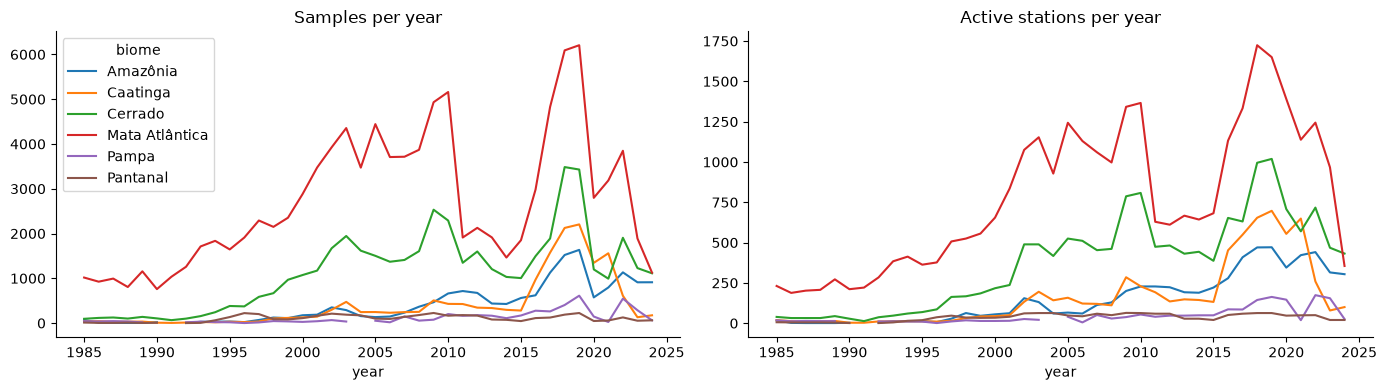

first_year,"[1985, 1990)","[1990, 1995)","[1995, 2000)","[2000, 2005)","[2005, 2010)","[2010, 2015)","[2015, 2020)","[2020, 2025)"
stations by first sampled year,497,219,505,1452,761,310,1997,460


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
s.groupby(["year", "biome"]).size().unstack().plot(ax=axes[0], title="Samples per year")
s.groupby(["year", "biome"])["station_code"].nunique().unstack().plot(ax=axes[1], title="Active stations per year", legend=False)
plt.tight_layout(); plt.show()

entry_cohort = per_station.groupby(pd.cut(per_station["first_year"], range(1985, 2030, 5), right=False)).size()
display(entry_cohort.rename("stations by first sampled year").to_frame().T)

Seasonality of sampling: month distribution by biome. Uneven wet/dry-season sampling interacts with runoff-driven pollution.

In [8]:
display(pd.crosstab(s["biome"], s["month"], normalize="index").round(3))

month,1,2,3,4,5,6,7,8,9,10,11,12
biome,,,,,,,,,,,,
Amazônia,0.036,0.093,0.084,0.076,0.093,0.078,0.084,0.101,0.086,0.089,0.11,0.069
Caatinga,0.044,0.09,0.089,0.074,0.089,0.1,0.087,0.095,0.091,0.081,0.092,0.069
Cerrado,0.038,0.085,0.093,0.073,0.088,0.096,0.081,0.093,0.095,0.092,0.1,0.069
Mata Atlântica,0.057,0.07,0.09,0.075,0.095,0.077,0.1,0.092,0.088,0.095,0.101,0.059
Pampa,0.058,0.092,0.091,0.063,0.103,0.09,0.071,0.103,0.082,0.077,0.105,0.065
Pantanal,0.036,0.072,0.093,0.079,0.103,0.087,0.1,0.095,0.083,0.09,0.111,0.05


**Findings (run of 2026-10-21).** - **Sampling design.** Monitoring is essentially quarterly: the median gap between
  samples is 92 days, and 86% of station-years have 1–4 samples. The median station
  contributes 19 samples over 7 distinct years. 4,999 stations (81%) pass the
  identifying rule.
- **Network expansion.** Coverage grows in two waves, 2000–05 (1,452 new stations) and
  2015–20 (1,997). National averages therefore mix entry with within-station change, so
  station FE and time FE are both required, and a balanced panel would be tiny.
- **Seasonality of sampling.** Samples are spread fairly evenly over the year (5–11% per
  month), with December–January under-sampled.

**→ Informs:** unit of analysis (sample-level vs station-year means), minimum panel
length per station, whether a balanced sub-panel is needed as robustness, and month /
season fixed effects.

## 3. Outcome coverage and candidate outcome set

In [9]:
def analyte_coverage(column):
    obs = s.loc[s[column].notna(), ["station_code", "year", "biome", "system_id"]]
    stations = obs.groupby("station_code").agg(n=("year", "size"), n_years=("year", "nunique"))
    identifying = stations[(stations.n >= MIN_SAMPLES_PER_STATION) & (stations.n_years >= MIN_YEARS_PER_STATION)]
    return {
        "type": TYPE_GROUP[column],
        "n_obs": len(obs),
        "n_stations": len(stations),
        "n_identifying_stations": len(identifying),
        "n_obs_identifying": int(identifying.n.sum()),
        "n_systems": obs["system_id"].nunique(),
        "n_biomes": obs["biome"].nunique(),
        "first_year": obs["year"].min() if len(obs) else np.nan,
        "last_year": obs["year"].max() if len(obs) else np.nan,
    }

coverage = (pd.DataFrame({column: analyte_coverage(column) for column in ANALYTES}).T
            .sort_values("n_identifying_stations", ascending=False))
CANDIDATES = coverage.index[coverage["n_identifying_stations"] >= MIN_IDENTIFYING_STATIONS].tolist()
print(f"{len(CANDIDATES)} of {len(ANALYTES)} analytes pass the screen "
      f"(>= {MIN_IDENTIFYING_STATIONS} identifying stations)")
display(coverage.loc[CANDIDATES])

70 of 131 analytes pass the screen (>= 100 identifying stations)


,type,n_obs,n_stations,n_identifying_stations,n_obs_identifying,n_systems,n_biomes,first_year,last_year
sample_temperature,other,187241,6115,4909,181777,260,6,1985,2024
ph,core_physicochemical,182299,6163,4861,176181,261,6,1985,2024
dissolved_oxygen,other,176174,6073,4832,170372,261,6,1985,2024
turbidity,core_physicochemical,163824,5962,4713,157870,260,6,1985,2024
biochemical_oxygen_demand,oxygen_demand_organic_load,113936,4401,3165,108737,227,6,1985,2024
ammoniacal_nitrogen,nutrients,100367,4198,2968,95325,243,6,1985,2024
total_phosphorus,nutrients,96799,4214,2898,91425,244,6,1985,2024
specific_conductivity,core_physicochemical,54690,4856,2871,45401,251,6,1999,2024
nitrates,nutrients,98764,4317,2858,93136,240,6,1985,2024
electrical_conductivity,core_physicochemical,108005,3947,2586,103871,190,6,1985,2024


In [10]:
display(coverage.assign(candidate=coverage.index.isin(CANDIDATES))
        .groupby("type").agg(analytes=("n_obs", "size"), candidates=("candidate", "sum")))

prior = pd.DataFrame(
    [(group, outcome) for group, outcomes in PRIOR_OUTCOME_GROUPS.items() for outcome in outcomes],
    columns=["group", "outcome"],
)
prior["in_panel"] = prior["outcome"].isin(ANALYTES)
prior["candidate"] = prior["outcome"].isin(CANDIDATES)
prior["n_identifying_stations"] = prior["outcome"].map(coverage["n_identifying_stations"])
display(prior)

,analytes,candidates
type,,
core_physicochemical,26,20
metals,25,19
microbiological,15,6
nutrients,12,9
organics_pesticides,37,3
other,10,8
oxygen_demand_organic_load,6,5


,group,outcome,in_panel,candidate,n_identifying_stations
0,pasture,thermotolerant_coliforms,True,True,755
1,pasture,fecal_coliforms,True,True,1644
2,pasture,escherichia,True,True,838
3,pasture,total_nitrogen,True,True,2152
4,pasture,ammoniacal_nitrogen,True,True,2968
5,pasture,total_phosphorus,True,True,2898
6,pasture,biochemical_oxygen_demand,True,True,3165
7,pasture,chemical_oxygen_demand,True,True,2305
8,pasture,chlorophyll,True,True,1532
9,pasture,cyanobacteria_density,False,False,NaN


Identifying stations per biome for each candidate — an effect estimated on a pooled panel may in practice be a Mata Atlântica effect.

In [11]:
def identifying_by_biome(column):
    obs = s.loc[s[column].notna()]
    stations = obs.groupby("station_code").agg(n=("year", "size"), n_years=("year", "nunique"), biome=("biome", "first"))
    stations = stations[(stations.n >= MIN_SAMPLES_PER_STATION) & (stations.n_years >= MIN_YEARS_PER_STATION)]
    return stations["biome"].value_counts()

display(pd.DataFrame({column: identifying_by_biome(column) for column in CANDIDATES}).T.fillna(0).astype(int))

biome,Amazônia,Caatinga,Cerrado,Mata Atlântica,Pampa,Pantanal
sample_temperature,464,706,1185,2302,174,78
ph,454,698,1165,2311,155,78
dissolved_oxygen,454,699,1167,2262,172,78
turbidity,450,666,1134,2214,171,78
biochemical_oxygen_demand,32,459,695,1818,106,55
ammoniacal_nitrogen,58,474,609,1658,109,60
total_phosphorus,44,474,595,1631,95,59
specific_conductivity,394,540,538,1191,152,56
nitrates,51,427,670,1642,13,55
electrical_conductivity,243,188,713,1315,58,69


Co-measurement: Jaccard overlap of samples between candidates. Low overlap means different outcomes are estimated on different station samples, so their coefficients are not directly comparable.

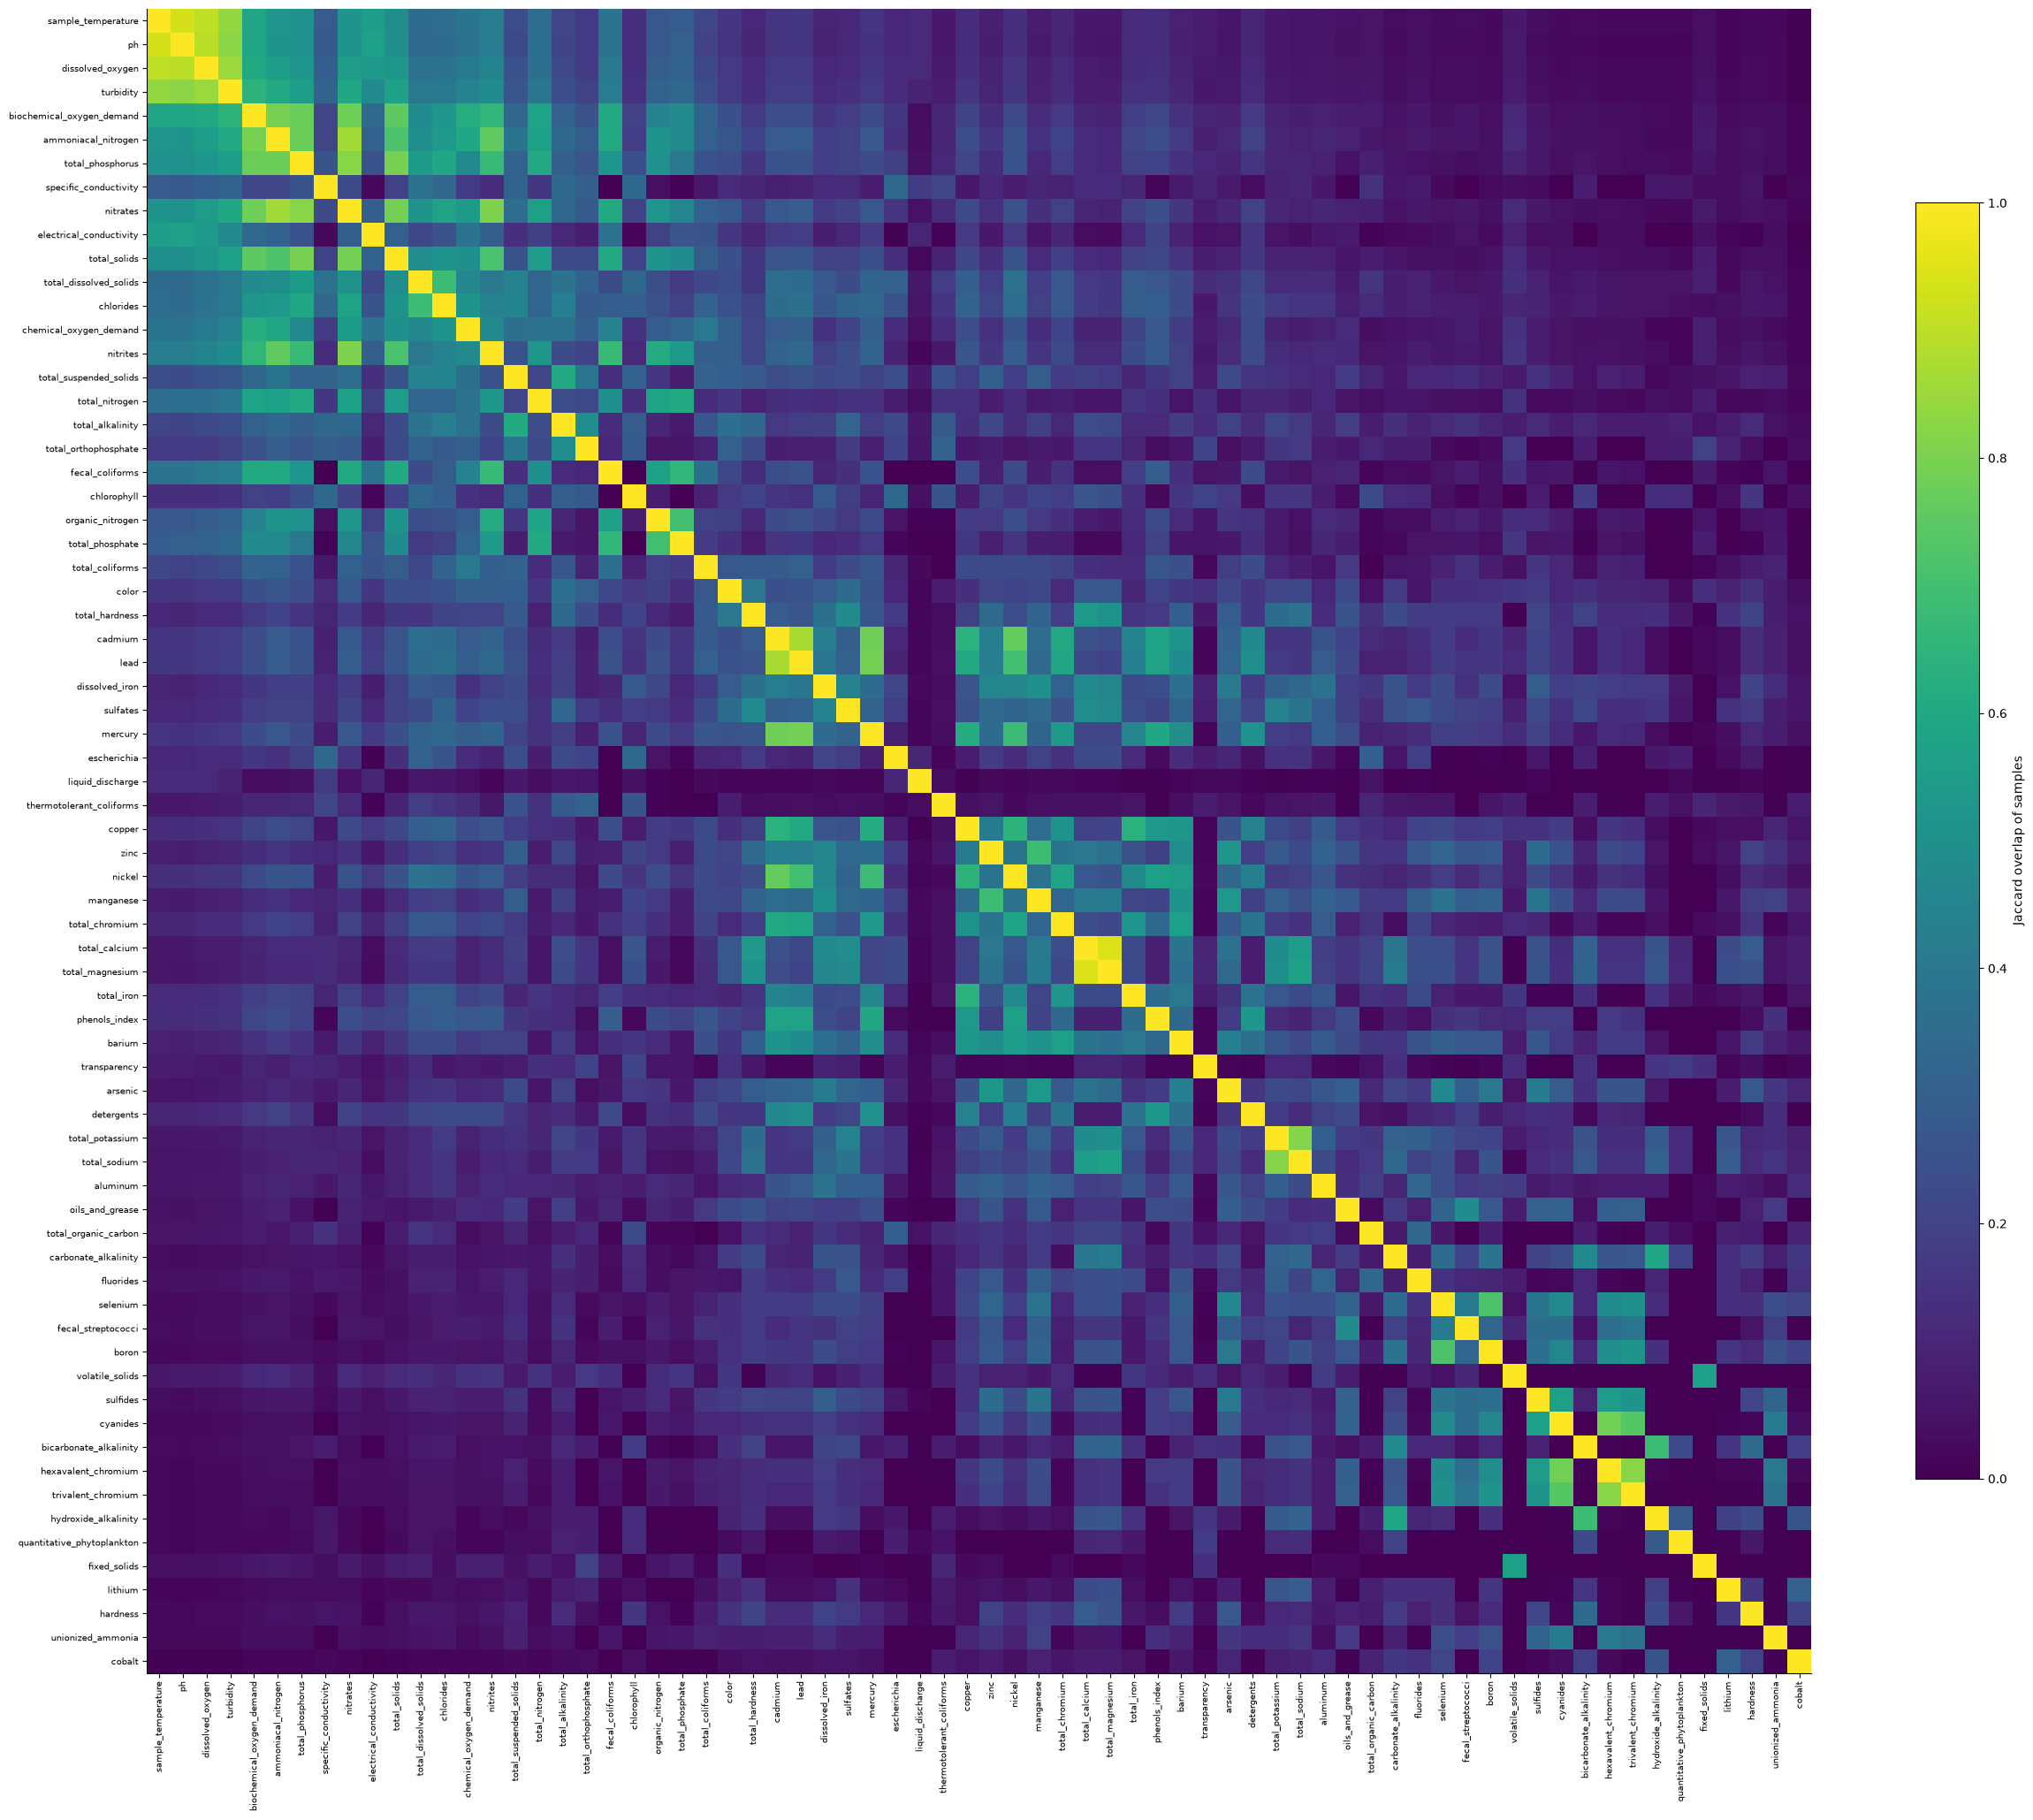

In [12]:
measured = s[CANDIDATES].notna().astype(np.int32)
intersection = measured.T @ measured
counts = np.diag(intersection)
jaccard = intersection / (counts[:, None] + counts[None, :] - intersection)

fig, ax = plt.subplots(figsize=(0.32 * len(CANDIDATES) + 3, 0.32 * len(CANDIDATES) + 2))
im = ax.imshow(jaccard, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CANDIDATES)), CANDIDATES, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.6, label="Jaccard overlap of samples")
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** - **Screen.** 70 of 131 analytes have at least 100 identifying stations. Every analyte
  in the earlier pasture/mining lists passes, except `cyanobacteria_density` (no longer
  in the fetch). Only 3 of 37 organics/pesticides pass, so pesticides cannot be studied
  with this panel.
- **Biome concentration.** Identifying stations are concentrated in the Mata Atlântica
  (47%). The Amazon has at most about 60 identifying stations for most nutrients and 26
  for fecal coliforms, so pooled estimates for those outcomes are effectively
  extra-Amazonian.
- **Different samples per family.** Core physicochemicals have about 150k samples,
  nutrients 70–100k, and metals only 15–30k. Coefficients across outcome families
  therefore come from different station samples.

**→ Informs:** the outcome set for `02_analysis` (replacing the hard-coded lists), whether
to estimate per biome, and whether to restrict to a common sample across outcomes.

## 4. Outcome distributions

In [13]:
TRANSFORMATIONS_PATH = (PROJECT_ROOT / "data/sensor_data/processed/extract/water_quality_cleaning"
                        / "sensor_data_water_quality_transformations.json")
RECOMMENDED_TRANSFORM = {
    column: spec["recommended_transform"]
    for column, spec in json.loads(TRANSFORMATIONS_PATH.read_text())["recommendations"].items()
}

distributions = desc.distribution_table(s, CANDIDATES)
distributions["recommended_transform"] = distributions.index.map(RECOMMENDED_TRANSFORM)
display(distributions)

,n,share_zero,share_negative,n_distinct,modal_value,modal_share,min,p01,median,p99,p999,max,skew,skew_log_positive,recommended_transform
sample_temperature,1.872e+05,0.005154,0,"3,638",24,0.03593,0,11.9,24.12,32,34.8,58,-0.9517,-1.322,identity
ph,1.823e+05,0.003335,0,"1,188",7,0.04325,0,4.54,7.05,9.03,11.04,14,-1.625,-2.253,identity
dissolved_oxygen,1.762e+05,0.008792,0,"1,792",7,0.02009,0,0.1,7,10.88,19,40,0.2838,-3.782,identity
turbidity,1.638e+05,0.01917,0,1.037e+04,0,0.01917,0,0,16,583.7,"2,287",8.34e+04,159.1,-0.2346,log10_1p
biochemical_oxygen_demand,1.139e+05,0.0203,0,"2,264",2,0.3546,0,0,2,68,231.1,4.664e+04,195.6,1.311,log10_1p
ammoniacal_nitrogen,1.004e+05,0.1385,0,"2,244",0.1,0.1388,0,0,0.1,17.3,37.85,"2,709",197.5,0.7192,log10_1p
total_phosphorus,9.68e+04,0.0685,0,"2,207",0.02,0.08947,0,0,0.07,3.55,60,"3,487",116.4,0.7246,log10_1p
specific_conductivity,5.469e+04,0.002048,0,"8,936",1,0.005522,0,1,77.3,"6,991",5.449e+04,3.76e+05,31.73,0.3095,log10_1p
nitrates,9.876e+04,0.1155,0,"2,284",0,0.1155,0,0,0.2,5.837,"1,300","5,750",36.64,0.6464,log10_1p
electrical_conductivity,1.08e+05,0.002611,0,1.009e+04,50,0.006065,0,0.069,61,"1,149",2.26e+04,1.108e+06,247,-1.602,log10_1p


Plausibility: values outside physical bounds (pH ∉ [0, 14] or exactly 0, DO above saturation-plausible 20 mg/L, water temperature outside 0–45 °C).

In [14]:
PLAUSIBLE_RANGES = {
    "ph": (0, 14),
    "dissolved_oxygen": (0, 20),
    "sample_temperature": (0, 45),
}
plausibility = {}
for column, (lower, upper) in PLAUSIBLE_RANGES.items():
    values = s[column].dropna()
    plausibility[column] = {
        "n": len(values),
        "below": (values < lower).sum(),
        "at_lower_bound": (values == lower).sum(),
        "above": (values > upper).sum(),
    }
display(pd.DataFrame(plausibility).T)

,n,below,at_lower_bound,above
ph,182299,0,608,0
dissolved_oxygen,176174,0,1549,146
sample_temperature,187241,0,965,5


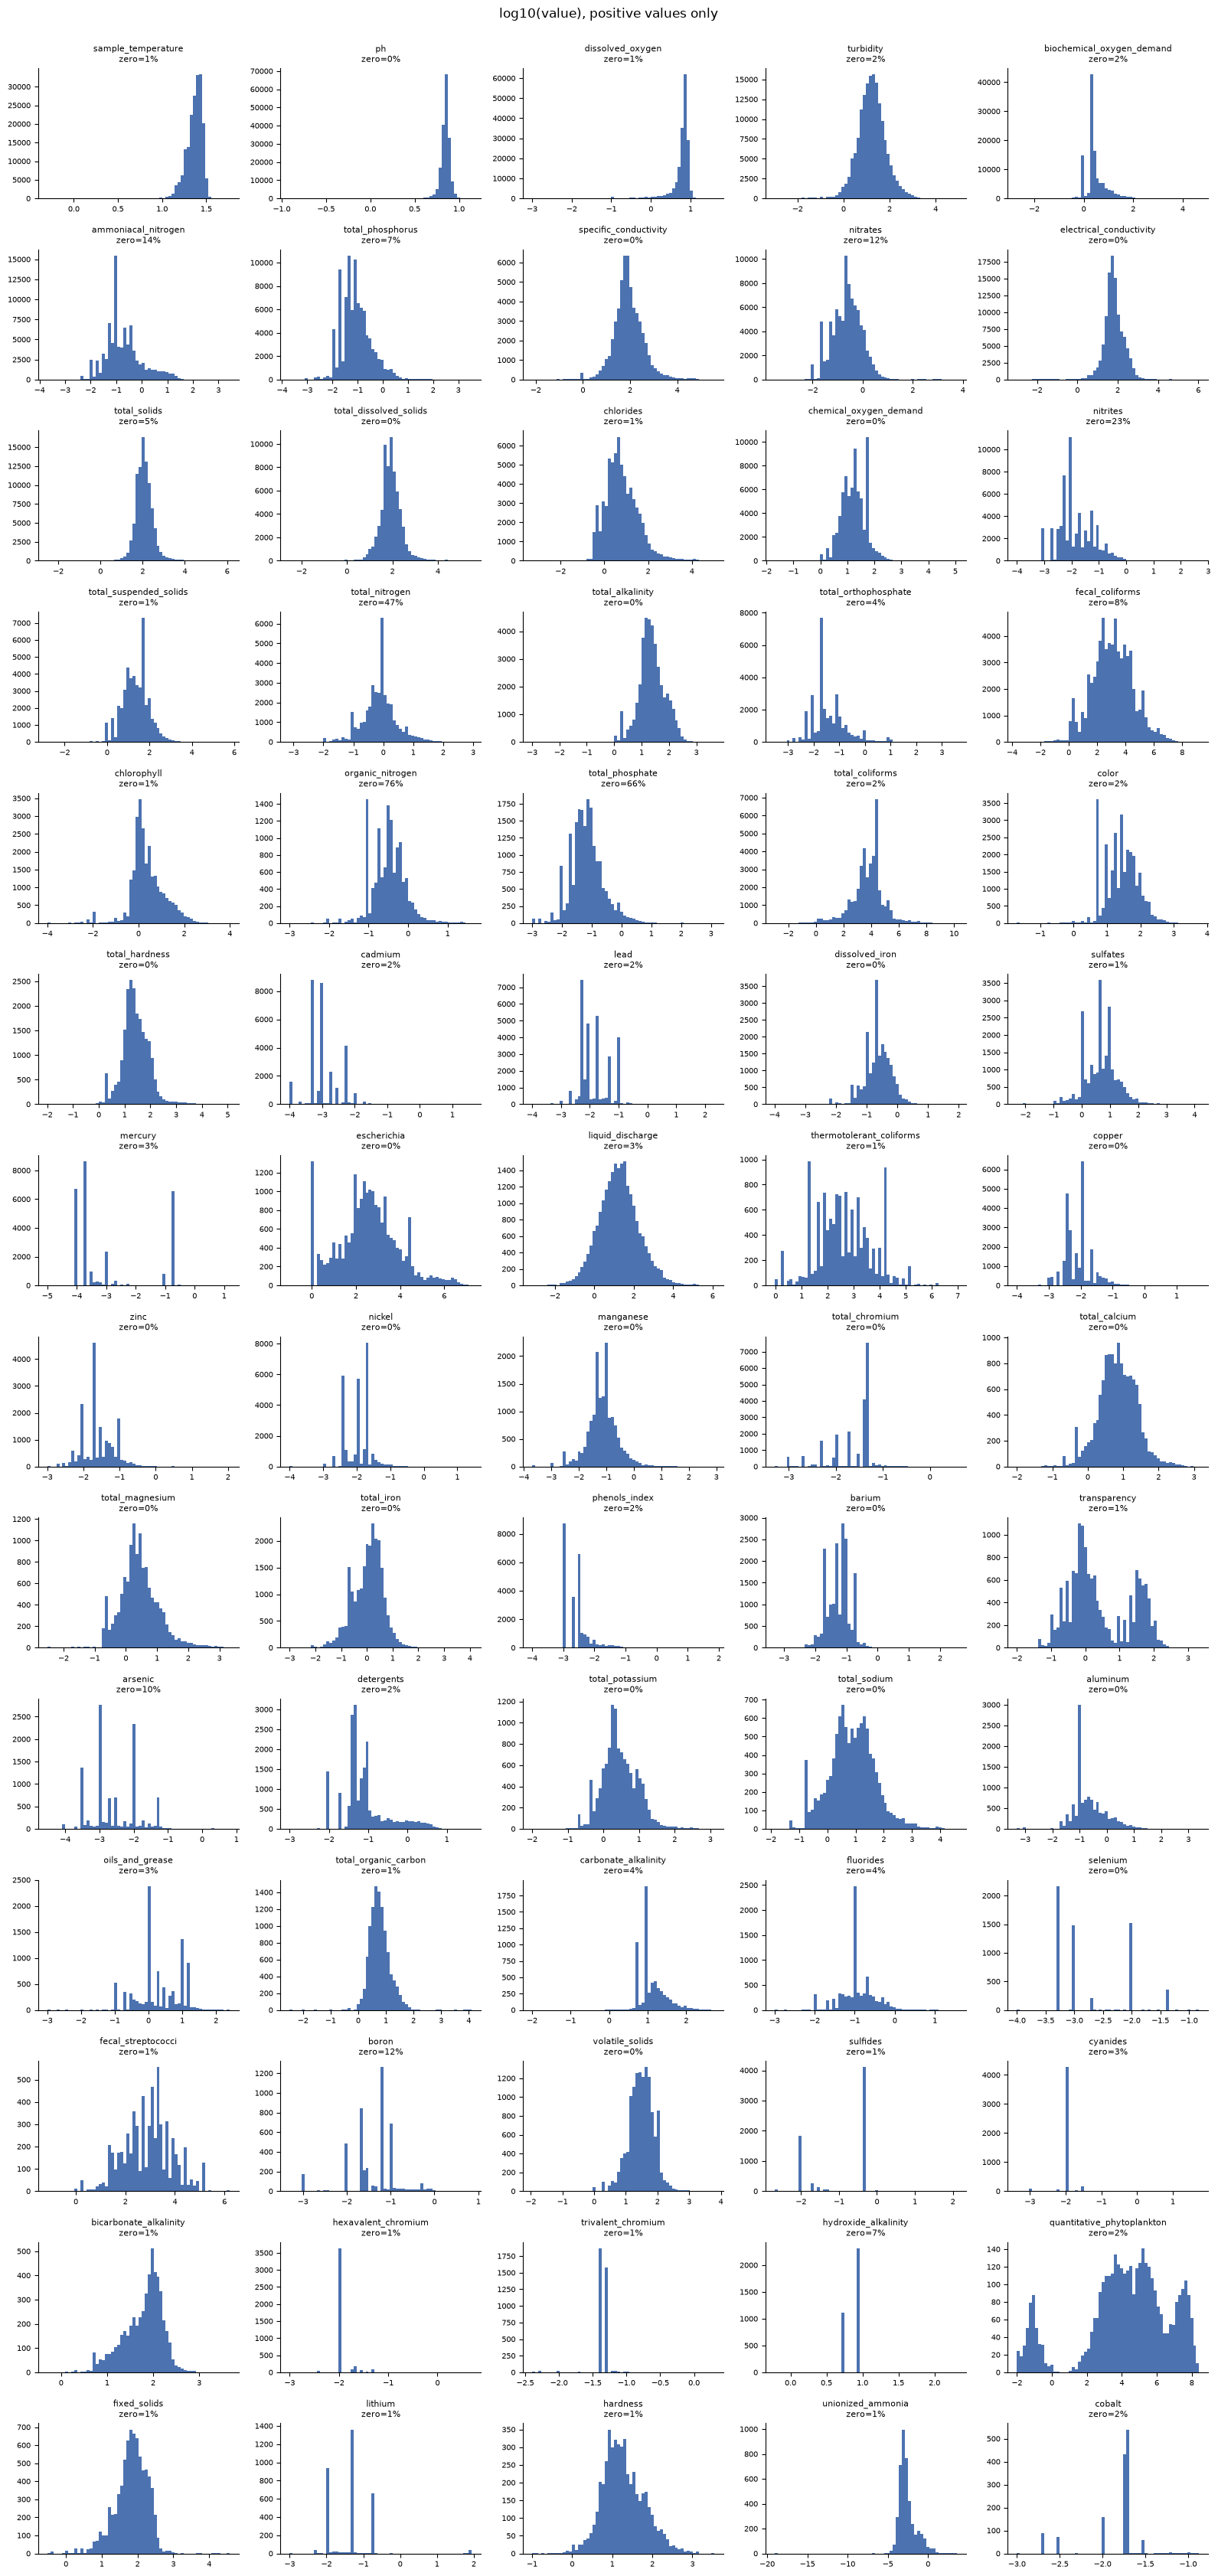

In [15]:
n_cols = 5
n_rows = int(np.ceil(len(CANDIDATES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.4 * n_rows))
for ax, column in zip(axes.flat, CANDIDATES):
    values = s[column].dropna()
    positive = values[values > 0]
    ax.hist(np.log10(positive), bins=60, color="#4C72B0")
    ax.set_title(f"{column}\nzero={1 - len(positive) / len(values):.0%}", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(CANDIDATES):]:
    ax.axis("off")
fig.suptitle("log10(value), positive values only", y=1.0)
plt.tight_layout(); plt.show()

Detection limits. The cleaned data carries no "below detection limit" qualifier, so
censoring has to be inferred: heaping at a single value (`modal_share` above) that
**changes over time** marks a lab reporting limit rather than a real concentration.
Where the limit moves by orders of magnitude, within-station change in the analyte
mostly tracks lab practice.

In [16]:
DL_CHECK = [c for c in ["cadmium", "lead", "mercury", "copper", "biochemical_oxygen_demand",
                        "total_phosphorus", "total_nitrogen"] if c in CANDIDATES]
period = s["year"] // 5 * 5
rows = []
for column in DL_CHECK:
    values = s[column].dropna()
    for start, group in values.groupby(period.loc[values.index]):
        modal = group.mode().iloc[0]
        rows.append({"analyte": column, "period": start, "n": len(group), "modal_value": modal,
                     "modal_share": (group == modal).mean(), "median": group.median()})
display(pd.DataFrame(rows).pivot(index="analyte", columns="period", values=["modal_value", "modal_share"]).round(4))

modal_value                                                modal_share                                                 
period                           1985   1990   1995   2000   2005  2010   2015  2020        1985   1990   1995   2000   2005   2010   2015   2020
analyte                                                                                                                                          
biochemical_oxygen_demand           1      1      2      2      2     2      2     2      0.4231   0.22 0.2676 0.3686 0.4271 0.4387 0.3851 0.2974
cadmium                             0  0.001  0.001 0.0005 0.0001 0.005 0.0005 0.001      0.3225  0.438 0.5888 0.4279 0.3129  0.893 0.5506 0.3036
copper                           0.01   0.01  0.004  0.004   0.01 0.008  0.005 0.005       0.771 0.2802 0.2929 0.3446 0.4879 0.5258 0.4107 0.4128
lead                                0   0.02   0.05    0.1   0.01  0.02  0.005  0.01      0.3048 0.4467 0.4091 0.2821 0.2828 0.7344 0.5434 0.3511
mercury                             0 0.0001 0.0002    0.2 0.0002   0.1    0.2   0.2      0.3042 0.5656 0.4597 0.3826 0.5756 0.9226 0.4637 0.3245
total_nitrogen                   0.48   0.24   0.01      0      0     0      1     1      0.0222 0.0203 0.0167 0.7845 0.7159 0.7447 0.2369 0.1507
total_phosphorus                 0.01   0.01   0.05      0   0.02  0.02   0.02  0.02      0.0516 0.0402 0.0759 0.2515  0.075 0.1175 0.1544 0.1094

**Findings (run of 2026-10-21).** - **Shape.** Levels are extremely right-skewed (skew 100–250 for turbidity, BOD, total
  solids). Logs of positive values are close to symmetric for most outcomes, which
  supports `log(y)`.
- **Zeros.** Under 10% for the core outcomes. The exceptions are total nitrogen (47%),
  nitrites (23%), organic nitrogen (76%) and total phosphate (66%).
- **Reporting limits.** Heaping marks reporting limits: 35% of BOD values sit at
  2 mg/L, and 23–36% of most metal values sit at a single modal value. That modal value
  moves over time by orders of magnitude for metals (mercury 0.0001 → 0.2 → 0.001), so
  within-station change in metals largely reflects lab practice.
- **Total nitrogen.** It is 72–78% zeros in 2000–14, then heaped at 1: a coding break.
- **Implausible values.** 608 pH = 0, 1,549 DO = 0 and 146 DO > 20 mg/L are coding
  artefacts.

**→ Informs:** outcome transform (log / log1p / IHS / level, or PPML on levels), treatment
of zeros and heaped values at detection limits (censoring vs. drop vs. indicator), and
outlier trimming / winsorization thresholds.

## 5. Outcome variance decomposition

Share of variance in the (recommended-transform) outcome left after absorbing each FE set. Low `station` share → little within-station signal to explain; high `station-year` share → most variation is intra-year (seasonal or measurement noise), which station-year aggregation would average away.

In [17]:
TRANSFORMS = {"identity": lambda x: x, "log10_1p": lambda x: np.log10(1 + x),
              "log10": lambda x: np.log10(x.where(x > 0))}

def transformed(column):
    return TRANSFORMS[RECOMMENDED_TRANSFORM.get(column, "identity")](s[column])

y = pd.DataFrame({column: transformed(column) for column in CANDIDATES})
y[["station_code", "year", "month", "biome_year"]] = s[["station_code", "year", "month", "biome_year"]]
y["station_year"] = y["station_code"] + "_" + y["year"].astype(str)

OUTCOME_FE_SETS = {
    "station": ["station_code"],
    "station + biome×year": ["station_code", "biome_year"],
    "station + biome×year + month": ["station_code", "biome_year", "month"],
    "station-year": ["station_year"],
}
outcome_variation = desc.variation_table(y, CANDIDATES, OUTCOME_FE_SETS)
display(outcome_variation.filter(like="share:"))

,share: station,share: station + biome×year,share: station + biome×year + month,share: station-year
sample_temperature,0.4919,0.4798,0.3167,0.3431
ph,0.6339,0.6139,0.612,0.3182
dissolved_oxygen,0.4899,0.4745,0.4538,0.2721
turbidity,0.6113,0.5954,0.5238,0.3914
biochemical_oxygen_demand,0.3889,0.3726,0.3717,0.2306
ammoniacal_nitrogen,0.3151,0.3015,0.2981,0.1612
total_phosphorus,0.3548,0.3493,0.3485,0.2116
specific_conductivity,0.2311,0.2103,0.2096,0.1214
nitrates,0.4049,0.346,0.3452,0.1814
electrical_conductivity,0.2628,0.2516,0.2499,0.118


Within-station seasonal profile for a few core outcomes.

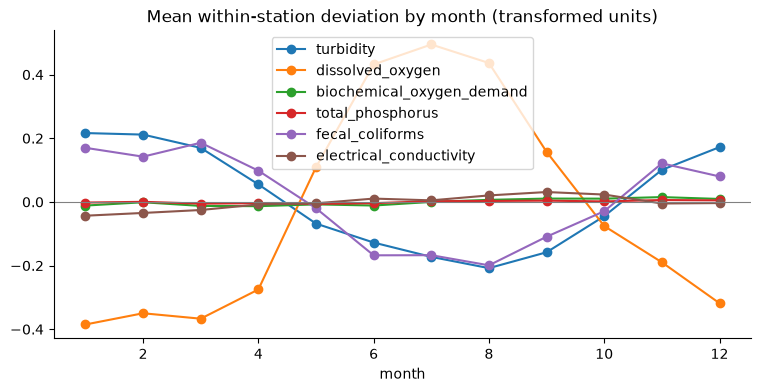

In [18]:
SEASONAL_OUTCOMES = [c for c in ["turbidity", "dissolved_oxygen", "biochemical_oxygen_demand",
                                 "total_phosphorus", "fecal_coliforms", "electrical_conductivity"] if c in CANDIDATES]
within_station = pd.DataFrame({c: y[c] - y.groupby("station_code")[c].transform("mean") for c in SEASONAL_OUTCOMES})
profile = within_station.groupby(y["month"]).mean()
profile.plot(figsize=(9, 4), marker="o", title="Mean within-station deviation by month (transformed units)")
plt.axhline(0, color="grey", lw=0.8); plt.show()

**Findings (run of 2026-10-21).** - **Station FE.** For most outcomes, 13–65% of variance remains after station FE
  (turbidity 61%, BOD 39%, TP 35%), so between-station differences dominate. Metals are
  the exception (cadmium 84%, lead 88% remaining), consistent with reporting-limit
  drift inside stations.
- **Time FE.** Biome×year FE remove little beyond station FE (≤ 5 pp). Month FE matter
  for water temperature (−16 pp), turbidity and TSS (−7 pp), and DO (−2 pp).
- **Intra-year noise.** About half to two-thirds of the within-station variance is
  within station-year, which is noise relative to annual land cover.
- **Seasonal profile.** DO peaks in June–August; turbidity and fecal coliforms peak in
  December–March (wet season). BOD, TP and EC look flat on the `log10(1+x)` scale. That
  is partly an artefact of the transform for small concentrations, one reason the
  analysis uses `log(y)`.

**→ Informs:** fixed-effect structure (station; biome×year vs year; month/season), and
whether to estimate at sample level or aggregate to station-year.

## 6. Land-cover exposure: levels and identifying variation

Land cover is annual, so variation is measured on station-years with at least one sample (the rows that actually enter estimation).

In [19]:
LC = panels.LAND_COVER_SHARE_COLUMNS
ALR = panels.LAND_COVER_ALR_COLUMNS
station_years = (s.dropna(subset=["lc_forest"])
                 .drop_duplicates(["station_code", "year"])
                 .loc[:, ["station_code", "year", "biome", "biome_year", "system_id", *LC, *ALR]])
station_years["identifying"] = station_years["station_code"].map(per_station["identifying"])
display(station_years[LC + ALR].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).T)

,count,mean,std,min,1%,10%,50%,90%,99%,max
lc_forest,5.829e+04,0.4193,0.251,0,0.04288,0.1339,0.3732,0.8121,0.9921,1
lc_nonforest_nat,5.829e+04,0.05449,0.122,0,0,9.099e-05,0.01349,0.1413,0.6171,1
lc_pasture,5.829e+04,0.2601,0.2064,0,0,0.01545,0.2216,0.5636,0.748,0.9801
lc_agriculture,5.829e+04,0.1079,0.1645,0,0,8.187e-05,0.02772,0.3499,0.6901,0.9576
lc_farming_unclassified,5.829e+04,0.1241,0.1006,0,0,0.004581,0.1101,0.2637,0.3925,0.7898
lc_urban,5.829e+04,0.02139,0.06946,0,0,7.694e-05,0.003833,0.04659,0.3205,1
lc_mining,5.829e+04,0.001164,0.007345,0,0,0,0,0.00124,0.02628,0.3334
lc_other,5.829e+04,0.001428,0.002645,0,0,3.541e-05,0.0007011,0.003277,0.01199,0.08687
lc_water,5.829e+04,0.01005,0.02192,0,0,0.0002622,0.003654,0.02461,0.1053,0.5256
alr_pasture,5.829e+04,-1.149,2.217,-9.21,-9.068,-3.695,-0.6532,0.912,1.948,6.87


In [20]:
EXPOSURE_FE_SETS = {
    "station": ["station_code"],
    "station + year": ["station_code", "year"],
    "station + biome×year": ["station_code", "biome_year"],
}
exposure_variation = desc.variation_table(station_years, LC + ALR, EXPOSURE_FE_SETS)
display(exposure_variation)

,n,sd_total,sd: station,share: station,sd: station + year,share: station + year,sd: station + biome×year,share: station + biome×year
lc_forest,5.829e+04,0.251,0.01904,0.005753,0.01734,0.00477,0.01484,0.003495
lc_nonforest_nat,5.829e+04,0.122,0.01012,0.00688,0.009904,0.006593,0.007187,0.003471
lc_pasture,5.829e+04,0.2064,0.03269,0.02507,0.03033,0.02159,0.02727,0.01745
lc_agriculture,5.829e+04,0.1645,0.02423,0.02168,0.0211,0.01645,0.02017,0.01504
lc_farming_unclassified,5.829e+04,0.1006,0.01966,0.03822,0.01788,0.03159,0.01718,0.02919
lc_urban,5.829e+04,0.06946,0.00561,0.006524,0.004874,0.004923,0.004742,0.00466
lc_mining,5.829e+04,0.007345,0.001528,0.04329,0.001502,0.04182,0.001496,0.04149
lc_other,5.829e+04,0.002645,0.0006098,0.05317,0.0006013,0.0517,0.0005859,0.04909
lc_water,5.829e+04,0.02192,0.004103,0.03504,0.004081,0.03468,0.003463,0.02497
alr_pasture,5.829e+04,2.217,0.2389,0.01162,0.2342,0.01116,0.2083,0.008827


Long differences within station (last minus first sampled year): how many stations see a material land-cover change at all?

In [21]:
ordered_sy = station_years.sort_values(["station_code", "year"])
first_obs = ordered_sy.groupby("station_code").first()
last_obs = ordered_sy.groupby("station_code").last()
long_diff = (last_obs[LC] - first_obs[LC])[(last_obs["year"] - first_obs["year"]) >= 5]
summary = long_diff.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
for threshold in (0.01, 0.05):
    summary[f"share |Δ| > {threshold:.0%}"] = (long_diff.abs() > threshold).mean()
print(f"Stations with >= 5 years between first and last sample: {len(long_diff):,}")
display(summary)

Stations with >= 5 years between first and last sample: 4,015


,count,mean,std,min,5%,25%,50%,75%,95%,max,share |Δ| > 1%,share |Δ| > 5%
lc_forest,"4,015",-0.02298,0.05171,-0.5633,-0.1175,-0.03561,-0.007442,0.004494,0.02432,0.1426,0.6182,0.1885
lc_nonforest_nat,"4,015",-0.005558,0.02651,-0.3948,-0.02908,-0.002663,-0.0002062,5.296e-05,0.003499,0.3133,0.1235,0.03512
lc_pasture,"4,015",-0.02216,0.08281,-0.5328,-0.1666,-0.05333,-0.0084,0.0118,0.08089,0.5614,0.7474,0.3614
lc_agriculture,"4,015",0.02591,0.05456,-0.1511,-0.01036,3.114e-05,0.004483,0.0306,0.1381,0.5226,0.4568,0.1898
lc_farming_unclassified,"4,015",0.01834,0.04615,-0.3249,-0.04016,-0.0001394,0.01196,0.03616,0.09575,0.2942,0.673,0.2115
lc_urban,"4,015",0.005701,0.01409,-0.0254,0,0.0002742,0.001241,0.004138,0.02652,0.1736,0.13,0.02267
lc_mining,"4,015",0.0008112,0.005459,-1.002e-05,0,0,0,5.427e-05,0.002337,0.1681,0.02067,0.001494
lc_other,"4,015",-0.0001733,0.001471,-0.02973,-0.00186,-0.0002581,0,0.0001918,0.001095,0.01145,0.003985,0
lc_water,"4,015",0.0001027,0.01021,-0.286,-0.00337,-0.0004925,5.313e-06,0.0005396,0.005918,0.2574,0.04209,0.004981


Extensive margin: the ALR transform adds a pseudocount, so an absent class maps to a large negative value (that depends on the natural share). Where many station-years have the class absent, or where it switches from absent to present, the ALR coefficient is driven by that jump rather than by marginal conversion.

In [22]:
ALR_SHARES = [c.replace("alr_", "lc_") for c in ALR]
absent = station_years[ALR_SHARES] == 0
switches = absent.groupby(station_years["station_code"]).agg(lambda x: x.any() and not x.all())
display(pd.DataFrame({
    "share_station_years_absent": absent.mean().values,
    "share_stations_ever_present": (~absent).groupby(station_years["station_code"]).any().mean().values,
    "share_stations_switching": switches.mean().values,
}, index=ALR))

,share_station_years_absent,share_stations_ever_present,share_stations_switching
alr_pasture,0.02393,0.9759,0.006236
alr_agriculture,0.06003,0.9458,0.03811
alr_farming_unclassified,0.0298,0.979,0.022
alr_urban,0.07863,0.9155,0.01057
alr_mining,0.558,0.4173,0.02633
alr_other,0.05481,0.9477,0.03568


Collinearity of the regressors after absorbing station + biome×year FE.

In [23]:
alr_within = desc.demean(station_years, ALR, ["station_code", "biome_year"])
corr = alr_within.corr()
display(corr.round(2))
vif = pd.Series(np.diag(np.linalg.inv(corr.to_numpy())), index=ALR, name="VIF (within)")
display(vif.to_frame().T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
alr_pasture,1,0.09,0.12,0.09,0.06,0.08
alr_agriculture,0.09,1,0.13,0.09,0.06,-0.04
alr_farming_unclassified,0.12,0.13,1,0.12,0.05,0.06
alr_urban,0.09,0.09,0.12,1,0.14,0.24
alr_mining,0.06,0.06,0.05,0.14,1,0.03
alr_other,0.08,-0.04,0.06,0.24,0.03,1


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
VIF (within),1.032,1.034,1.043,1.099,1.025,1.068


**Findings (run of 2026-10-21).** - **Composition.** Upstream land is on average 42% forest, 26% pasture and 11%
  agriculture. Urban (2%) and mining (0.1%) are small.
- **Identifying variation.** After station + biome×year FE, only 0.3–5% of each share's
  variance remains: forest 0.35%, pasture 1.7%, agriculture 1.5%, mining 4.1%. For the
  ALR terms it is 0.4–1.4%. Identification rests on a thin slice of the data, so wide
  confidence intervals are expected.
- **Long differences.** They are substantial even so. Among stations sampled at least 5
  years apart, 36% saw upstream pasture move by more than 5 pp, 19% forest and 19%
  agriculture.
- **Mining.** It is absent upstream in 56% of station-years, and only 2.6% of stations
  switch, so mining is mostly an extensive-margin regressor (hence the separate mining
  arm).
- **Collinearity.** Within-FE correlations among the ALR regressors are at most 0.24
  (VIF ≤ 1.1), so collinearity is not a concern.

**→ Informs:** which land-cover classes have enough within-station variation to be
estimated (vs. absorbed by FE), ALR vs. raw shares vs. changes, whether mining is
estimable as a continuous regressor or only as an indicator, and how much the FE
structure costs in identifying variation.

## 7. Upstream distance structure

The assembled `lc_*`/`alr_*` collapse 25 km upstream rings with an `inv_sqrt_distance`
kernel (`src/data/sources/land_cover/composition.py`). This section reads the bucket-level
input to check whether that collapse is innocuous: how far upstream stations reach, how
composition varies with distance, and whether near and far rings move independently
enough to estimate distance-specific effects.

In [24]:
from src.data.shared.sensor_upstream import bucket_kernel_weights
from src.data.sources.land_cover.constants import LAND_COVER_COMPOSITION_BUCKET_MAP

LC_BUCKETED_PATH = PROJECT_ROOT / "data/land_cover/processed/aggregate/land_cover_sensor_upstream.parquet"
CLASS_LABELS = {1: "forest", 30: "pasture", 31: "agriculture", 40: "urban", 41: "mining"}
sampled = station_years[["station_code", "year"]]
buckets = pd.read_parquet(
    LC_BUCKETED_PATH,
    filters=[("land_cover_class", "in", list(CLASS_LABELS)),
             ("year", ">=", first_year), ("year", "<=", last_year)],
).merge(sampled, on=["station_code", "year"])
buckets["class"] = buckets["land_cover_class"].map(CLASS_LABELS)

# The bucketed table pads every station with all rings; empty rings have n == 0.
reach = buckets[buckets["n"] > 0].groupby("station_code")["bucket"].max()
display(reach.value_counts().sort_index().rename("stations by furthest upstream bucket (km)").to_frame().T)

bucket,0,25,50,75,100,125,150,175,200,225,250,275,300,325,350,375,400,425,450,475,500
stations by furthest upstream bucket (km),857,764,546,454,350,301,239,217,184,146,131,110,102,118,84,52,49,59,53,47,910


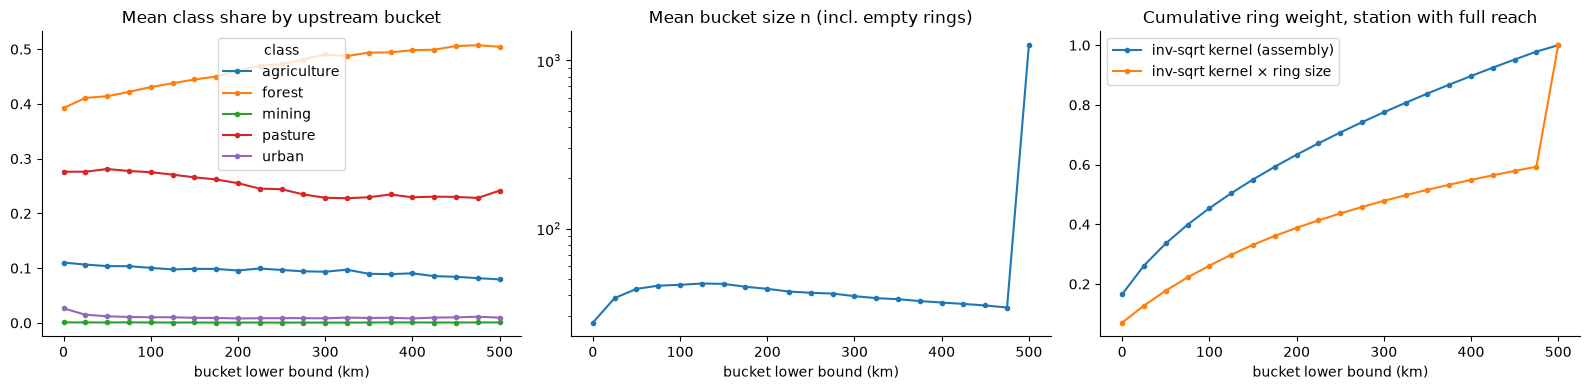

In [25]:
bucket_area = buckets.drop_duplicates(["station_code", "year", "bucket"]).groupby("bucket")["n"].mean()  # padded rings count as 0
mean_share = buckets.pivot_table(index="bucket", columns="class", values="share", aggfunc="mean")
midpoints = [LAND_COVER_COMPOSITION_BUCKET_MAP[b][1] for b in bucket_area.index]
weights = pd.Series(bucket_kernel_weights(midpoints, kernel="inv_sqrt_distance"), index=bucket_area.index)
# Assembly weights rings by kernel only (renormalized over the rings a station has);
# ring area does not enter. Kernel x area is shown for comparison.
kernel_only = weights / weights.sum()
area_weighted = (weights * bucket_area) / (weights * bucket_area).sum()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
mean_share.plot(ax=axes[0], marker=".", title="Mean class share by upstream bucket")
bucket_area.plot(ax=axes[1], marker=".", logy=True, title="Mean bucket size n (incl. empty rings)")
kernel_only.cumsum().plot(ax=axes[2], marker=".", label="inv-sqrt kernel (assembly)")
area_weighted.cumsum().plot(ax=axes[2], marker=".", label="inv-sqrt kernel × ring size")
axes[2].set_title("Cumulative ring weight, station with full reach"); axes[2].legend()
for ax in axes: ax.set_xlabel("bucket lower bound (km)")
plt.tight_layout(); plt.show()

Within-station correlation of class shares across distance rings (after removing station-bucket means). Correlations near 1 mean distance gradients are not separately identified and the kernel choice matters little; low correlations make distance-band coefficients feasible.

In [26]:
RING_SUBSET = [0, 25, 50, 100, 200, 300, 500]
for land_cover_class in ["pasture", "forest"]:
    wide = (buckets[(buckets["class"] == land_cover_class) & buckets["bucket"].isin(RING_SUBSET)]
            .pivot_table(index=["station_code", "year"], columns="bucket", values="share"))
    within = wide - wide.groupby(level="station_code").transform("mean")
    print(f"{land_cover_class}: within-station correlation across rings")
    display(within.corr().round(2))

pasture: within-station correlation across rings


bucket,0,25,50,100,200,300,500
bucket,,,,,,,
0,1,0.87,0.79,0.68,0.55,0.48,0.44
25,0.87,1,0.89,0.76,0.6,0.5,0.41
50,0.79,0.89,1,0.82,0.65,0.51,0.42
100,0.68,0.76,0.82,1,0.73,0.59,0.47
200,0.55,0.6,0.65,0.73,1,0.73,0.52
300,0.48,0.5,0.51,0.59,0.73,1,0.53
500,0.44,0.41,0.42,0.47,0.52,0.53,1


forest: within-station correlation across rings


bucket,0,25,50,100,200,300,500
bucket,,,,,,,
0,1,0.82,0.74,0.62,0.56,0.5,0.52
25,0.82,1,0.85,0.68,0.6,0.53,0.5
50,0.74,0.85,1,0.76,0.65,0.59,0.52
100,0.62,0.68,0.76,1,0.73,0.65,0.58
200,0.56,0.6,0.65,0.73,1,0.77,0.59
300,0.5,0.53,0.59,0.65,0.77,1,0.59
500,0.52,0.5,0.52,0.58,0.59,0.59,1


**Findings (run of 2026-10-21).** - **Reach.** Upstream reach varies enormously: 857 stations have land only in the first
  25 km ring, while 910 reach the 500 km+ catch-all.
- **Composition by distance.** Forest share rises with distance (about 0.39 near to
  0.50 far) and pasture falls (0.28 to 0.23). Urban land is concentrated in the nearest
  ring.
- **Assembled weighting.** It weights rings by the inv-sqrt kernel only, not by area.
  For a full-reach station the first 50 km carry about 26% of the weight and the
  500 km+ ring 2%; capping at 200 km raises the first 50 km to 44%.
- **Separability.** Within station, adjacent rings correlate about 0.87, but the
  nearest and farthest rings only 0.44. Distance bands are therefore partly separable,
  with wide intervals expected.

**→ Informs:** kernel and bandwidth (or replacing the kernel by distance-band regressors),
the maximum upstream reach to include, and whether area weighting dominates the kernel.

## 8. Controls: climate and streamflow

,count,mean,std,min,25%,50%,75%,max
tp_mean_day,1.83e+05,3.609,7.205,-1.863e-05,0.01094,0.5297,3.844,181.5
tp_mean_7d,1.83e+05,3.743,4.459,0,0.3601,2.153,5.698,76.03
tp_mean_30d,1.83e+05,3.695,3.231,0.0004307,1.033,2.944,5.583,29.12
tp_mean_90d,1.83e+05,3.734,2.744,0.0007191,1.511,3.278,5.416,21.36
tp_mean_180d,1.83e+05,3.842,2.193,0.01038,2.101,3.613,5.289,21.17
tp_mean_365d,1.83e+05,3.894,1.406,0.1929,2.97,3.784,4.664,21.17
sro_mean_day,1.83e+05,0.2913,1.539,-1.49e-05,7.302e-05,0.004038,0.04778,169.6
sro_mean_7d,1.83e+05,0.3101,0.8921,-6.652e-07,0.002228,0.02284,0.2883,44.26
sro_mean_30d,1.83e+05,0.3049,0.5826,0,0.007847,0.08946,0.3877,17.82
sro_mean_90d,1.83e+05,0.3102,0.4641,0,0.02343,0.1602,0.4165,9.04


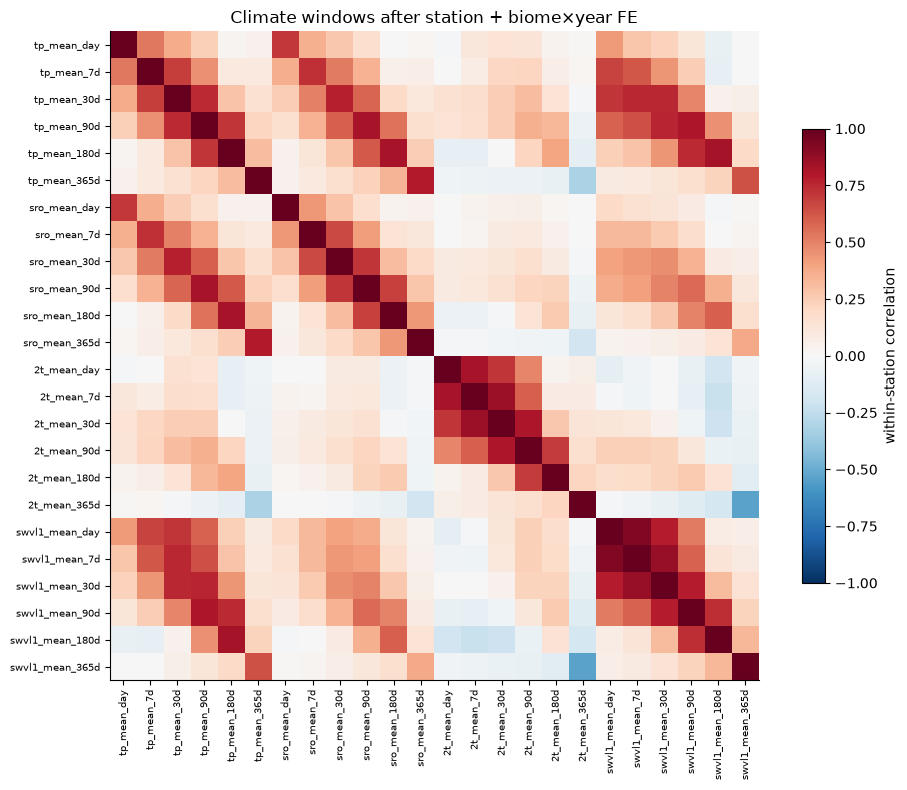

In [27]:
CLIMATE_SUBSET = panels.sensor_climate_columns(["tp", "sro", "2t", "swvl1"])
display(s[CLIMATE_SUBSET].describe().T)
climate_within = desc.demean(s, CLIMATE_SUBSET, ["station_code", "biome_year"])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(climate_within.corr(), vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(CLIMATE_SUBSET)), CLIMATE_SUBSET, rotation=90, fontsize=7)
ax.set_yticks(range(len(CLIMATE_SUBSET)), CLIMATE_SUBSET, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label="within-station correlation")
ax.set_title("Climate windows after station + biome×year FE")
plt.tight_layout(); plt.show()

Streamflow: coverage, distance to the matched gauge, and how much of discharge is explained by upstream precipitation/runoff (if almost all, discharge adds little beyond climate; it is also plausibly affected by land cover itself → bad-control risk).

In [28]:
display(s["streamflow_nearest_distance_m"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).rename("gauge distance (m)").to_frame().T)
flow = s[["station_code", "biome_year", "streamflow_discharge_day", "tp_mean_day", "tp_mean_7d", "sro_mean_7d", "tp_mean_30d"]].copy()
flow["log_discharge"] = np.log(flow.pop("streamflow_discharge_day").where(lambda q: q > 0))
flow_within = desc.demean(flow, ["log_discharge", "tp_mean_day", "tp_mean_7d", "sro_mean_7d", "tp_mean_30d"], ["station_code", "biome_year"])
display(flow_within.corr().loc[["log_discharge"]].round(3))

,count,mean,std,min,25%,50%,75%,90%,max
gauge distance (m),1.836e+05,30.34,102,0,0,0,23.84,75.08,"1,775"


,log_discharge,tp_mean_day,tp_mean_7d,sro_mean_7d,tp_mean_30d
log_discharge,1,0.133,0.311,0.224,0.406


**Findings (run of 2026-10-21).** - **Climate windows.** Within station, adjacent windows of one variable correlate
  0.7–0.9, but the nine chosen controls are at most 0.73 apart (7-day precipitation vs
  7-day runoff), so the set is not redundant.
- **Discharge.** It is matched at the gauge for 94% of samples (median distance 0 m) and
  correlates 0.13–0.41 with precipitation windows. It therefore carries information
  beyond the climate controls, but it is downstream of land cover (runoff), so it
  belongs in robustness rather than the baseline.

**→ Informs:** which climate windows to keep (collapse near-duplicates), whether to
control for discharge (dilution) or treat it as a mediator, and whether land-cover ×
runoff interactions have independent variation.

## 9. Inference structure

In [29]:
system_sizes = s.groupby("system_id").agg(n_stations=("station_code", "nunique"), n_samples=("datetime", "size"))
system_sizes = system_sizes.sort_values("n_samples", ascending=False)
system_sizes["cumulative_share"] = system_sizes["n_samples"].cumsum() / system_sizes["n_samples"].sum()
print(f"River systems: {len(system_sizes)}; effective number (inverse HHI, by samples): "
      f"{desc.effective_cluster_count(system_sizes['n_samples']):.1f}")
display(system_sizes.head(10))

otto = pd.DataFrame({
    level: {
        "clusters": s[level].nunique(),
        "effective (inverse HHI)": desc.effective_cluster_count(s.groupby(level).size()),
        "largest share": s.groupby(level).size().max() / s[level].notna().sum(),
    }
    for level in ["system_id", "otto_basin_l2", "otto_basin_l3", "otto_basin_l4", "otto_basin_l5"]
}).T
display(otto)

cells = s.groupby("biome_year")["station_code"].nunique()
display(cells.describe(percentiles=[0.05, 0.25, 0.5]).rename("stations per biome×year cell").to_frame().T)

River systems: 261; effective number (inverse HHI, by samples): 5.0


,n_stations,n_samples,cumulative_share
system_id,,,
2,1948,81052,0.4202
6,734,20502,0.5265
0,448,12040,0.5889
8,221,11154,0.6468
11,438,8188,0.6892
18,170,7873,0.73
48,137,3076,0.746
10,110,2800,0.7605
14,74,2483,0.7734


,clusters,effective (inverse HHI),largest share
system_id,261,4.997,0.4202
otto_basin_l2,42,5.287,0.3295
otto_basin_l3,207,27.21,0.09296
otto_basin_l4,843,98.21,0.04489
otto_basin_l5,"2,276",347.2,0.02026


,count,mean,std,min,5%,25%,50%,max
stations per biome×year cell,235,261.1,351.6,1,4.7,28,85,"1,724"


**Findings (run of 2026-10-21).** - **River systems are too coarse.** There are 261 of them, but one holds 42% of samples,
  for an effective number of 5.0. Otto level-3 sub-basins give 207 clusters (effective
  27, largest 9%), which is the level used for inference.
- **Small cells.** Biome×year cells hold a median of 85 stations, but 5% have fewer
  than 5 (early Pantanal and Pampa years). Those FE are close to station-specific.

**→ Informs:** cluster level (river system vs. Otto sub-basin vs. station / two-way with year), need for
wild-cluster bootstrap when a few systems dominate, and whether biome×year FE are
estimable for small biomes (Pantanal, Pampa).

## 10. Raw within-station associations

Binned scatter of outcome vs. regressor, both residualized on station + biome×year FE. Purely descriptive: sign and shape priors for the model, not estimates.

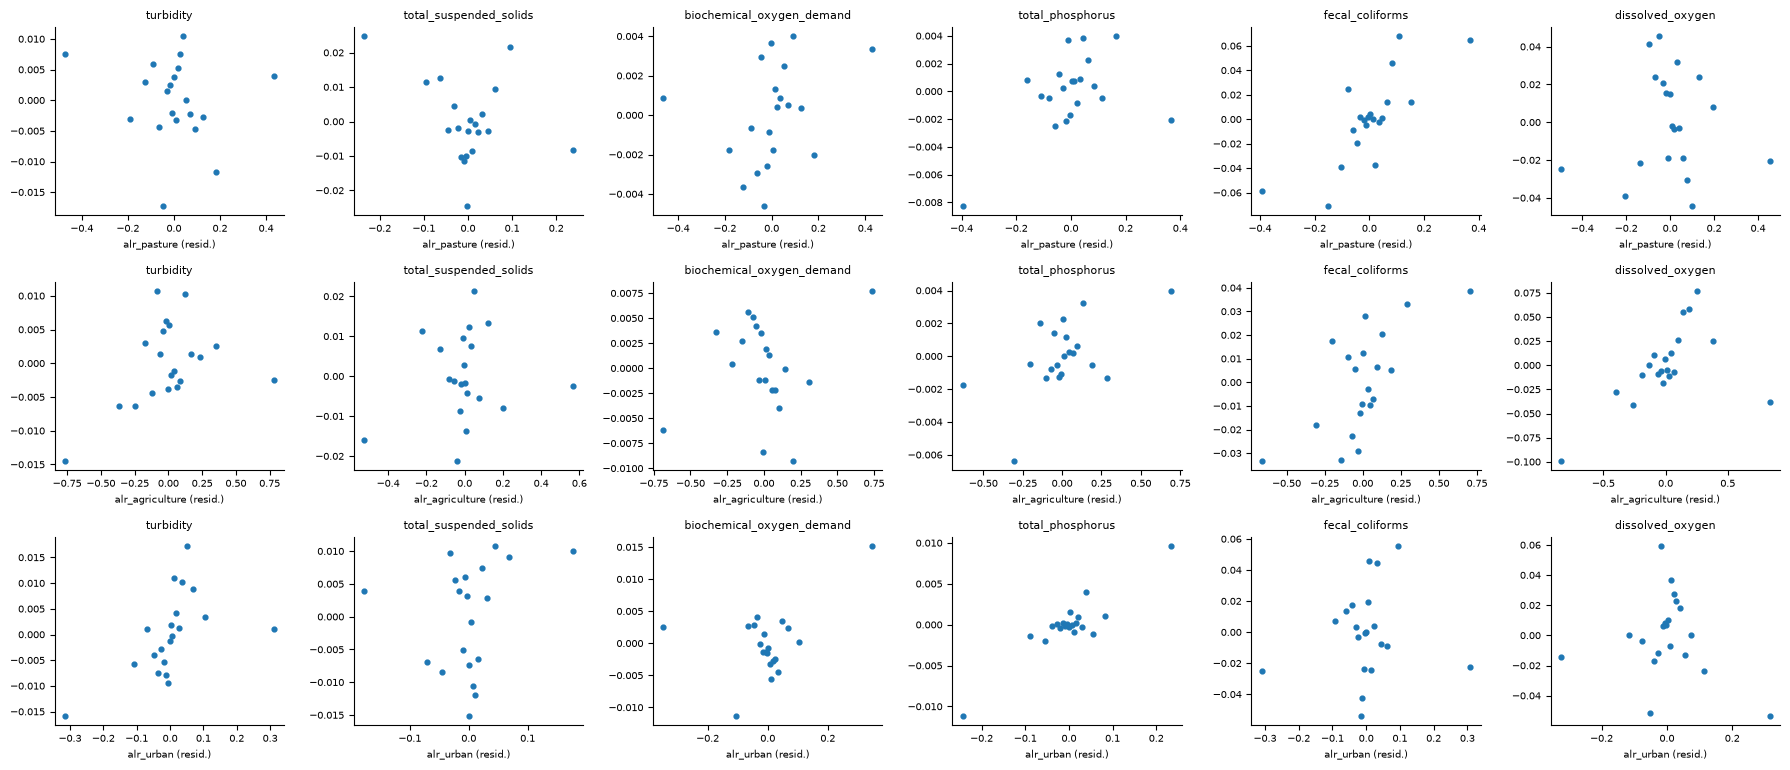

In [30]:
KEY_OUTCOMES = [c for c in ["turbidity", "total_suspended_solids", "biochemical_oxygen_demand",
                            "total_phosphorus", "fecal_coliforms", "dissolved_oxygen"] if c in CANDIDATES]
KEY_REGRESSORS = ["alr_pasture", "alr_agriculture", "alr_urban"]

frame = y[["station_code", "biome_year"] + KEY_OUTCOMES].join(s[KEY_REGRESSORS])
fig, axes = plt.subplots(len(KEY_REGRESSORS), len(KEY_OUTCOMES),
                         figsize=(3 * len(KEY_OUTCOMES), 2.6 * len(KEY_REGRESSORS)), squeeze=False)
for i, regressor in enumerate(KEY_REGRESSORS):
    for j, outcome in enumerate(KEY_OUTCOMES):
        residuals = desc.demean(frame, [outcome, regressor], ["station_code", "biome_year"])
        bins = desc.binscatter(residuals[regressor], residuals[outcome])
        axes[i, j].scatter(bins["x"], bins["y"], s=12)
        axes[i, j].set_title(f"{outcome}", fontsize=8)
        axes[i, j].set_xlabel(f"{regressor} (resid.)", fontsize=7)
        axes[i, j].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** After FE, the residualized regressors span only about ±0.4 ALR units, and the binned
scatters are noisy.
- **Visible slopes.** Fecal coliforms rise with pasture, DO rises with agriculture, and
  TP rises with urban land.
- **Shape.** There is no evidence of strong nonlinearity, so linear terms are adequate.
  The weak signal is consistent with the thin identifying variation in §6.

**→ Informs:** expected signs, linearity vs. need for nonlinear terms, and whether the
signal is concentrated in the tails of the regressor.

## 11. Decision table

Status (2026-10-21): all rows **decided** and implemented in `src/analysis/pollution.py` /
`02_analysis.ipynb`.

| Parameter | Current (`02_analysis`) | Evidence | Proposal | Status |
|---|---|---|---|---|
| Estimation window | year ≥ 1970 | §1: exposure exists 1985–2024 only | 1985–2024, complete cases on exposure (drops the 428 unsnapped stations) | decided |
| Station inclusion | none | §2: 4,999 of 6,201 stations have ≥ 8 samples in ≥ 3 years | Identifying-station rule as in the screening parameters | decided |
| Unit of analysis | sample | §5: 40–65% of within-station variance is intra-year; LC × runoff needs sample timing | Sample level; station-year means as robustness | decided |
| Fixed effects | station + biome×year | §5: month FE remove a further 4–34% of the remaining variance (DO, turbidity, TSS, water temperature); wet seasons differ by biome | station + biome×year + biome×month | decided |
| Outcome set | hard-coded pasture/mining lists | §3, §4 | Core: turbidity, TSS, DO, BOD, COD, TP, ammoniacal N, nitrates, fecal indicator, EC, pH. Total N excluded (72–78% zeros in 2000–14, then heaped at 1: a coding break). Metals only as exceedance indicators (see below) | decided |
| Fecal indicator | three separate outcomes | §3: fecal coliforms (1,644 stations), *E. coli* (838), thermotolerant (755) measured at different stations; the indicator changed with regulation | One combined series: fecal/thermotolerant coliforms (identical where both reported), else *E. coli*; station × indicator-type FE | decided |
| Outcome transform | `log(y)`, zeros dropped | §4: log of positives is near-symmetric for core outcomes; the JSON's `log10(1+x)` is unit-dependent and ≈ linear for small concentrations (TP median 0.07 mg/L) | `log(y)`; never `log10(1+x)`. PPML on levels as robustness | decided |
| Detection limits | none | §4: BOD ~40% at 2 mg/L; metals' reporting limit moves by orders of magnitude over time; no censoring flag in the data | Continuous outcomes in logs as is (PPML on levels as robustness keeps the non-detects). Parallel outcome family: CONAMA 357 class-2 violation indicators; station-periods whose reporting limit is at or above the CONAMA limit are excluded. Metals enter only through this family; aluminum and copper are excluded (dissolved-fraction limits vs total in the panel) | decided |
| Implausible values / outliers | none | §4: pH = 0 (608), DO = 0 (1,549), DO > 20 (146), EC up to 1.1e6 | Drop pH ∉ (0, 14] and DO ∉ (0, 20]; trim above p99.9 per analyte (or reuse the cleaning step's `flag_extreme_review`, which is not yet carried into the panel) | decided |
| Land-cover regressors | ALR pasture, agriculture, urban, mining, other | §6: within VIF ≈ 1; `alr_farming_unclassified` (12% mean share, largest within variation) is omitted | Add `alr_farming_unclassified`. Expect wide CIs: about 1% of ALR variance is identifying | decided |
| Mining | continuous ALR in the main model | §6: 56% of station-years have no mining upstream; 2.6% of stations switch | Out of the main model. Separate mining arm (not started; see README) | decided |
| Distance kernel / reach | inv-sqrt over all rings incl. 500 km+ | §7: 857 stations reach only the first ring and 910 the 500 km+ ring; adjacent rings correlate 0.87, near vs far 0.44 | Main: inv-sqrt capped at 200 km. Robustness: distance bands 0–50 / 50–150 / 150–500 km (computable from the bucketed file) | decided |
| Climate controls | tp 1/7/365, sro 7, swvl1 30, swvl2 90, ssro 180, pev 365, t2m 365 | §8: adjacent windows of one variable correlate 0.7–0.9, but the nine chosen ones are at most 0.73 apart (tp 7d vs sro 7d); no short-run temperature although DO depends on it | Keep the nine, add `2t_mean_7d` | decided |
| Streamflow / discharge | excluded | §8: 94% coverage, gauge median 0 m away; discharge is downstream of land cover (runoff) | Excluded from main (mediator); include as a dilution robustness check | decided |
| Interactions | ALR × `sro_7d` | §8 | Keep pasture and agriculture × `sro_7d` | decided |
| Clustering | system + year | §9: 261 systems but effective ≈ 5 (one system holds 42%) | Otto level-3 sub-basins (`otto_basin_l3`, from `river_network_otto_basins.parquet`; effective ≈ 27 vs ≈ 5 for `system_id`). Station + year, Otto 2/4 and Otto 3 + year as sensitivity | decided |
| Heterogeneity | none | §3: identifying stations are 47% Mata Atlântica; Amazon has ≤ 60 for most nutrients | Pooled main; biome interactions only for turbidity, DO, pH, EC (all biomes covered) | decided |